<a href="https://colab.research.google.com/github/rohillatanisha676-del/CODSOFT_TASKNO/blob/main/Churn_Modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded.keys())))

print("Dataset Shape:", df.shape)
display(df.head())

Saving Churn_Modelling.csv to Churn_Modelling (1).csv
Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
# Remove unnecessary columns
df = df.drop(
    columns=["RowNumber", "CustomerId", "Surname"],
    errors="ignore"
)

# Input features and target
X = df.drop("Exited", axis=1)
y = df["Exited"]

print("Features:", X.columns.tolist())
print("\nCustomer churn distribution:")
print(y.value_counts())

Features: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Customer churn distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 8000
Testing records: 2000


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing completed!")

Preprocessing completed!


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, predictions, zero_division=0) * 100, 2
        )
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Logistic Regression,80.8,58.91,18.67,28.36
1,Random Forest,85.8,77.33,42.75,55.06
2,Gradient Boosting,86.9,78.21,49.39,60.54


In [7]:
best_name = results_df.loc[
    results_df["F1 Score (%)"].idxmax(), "Model"
]

best_model = trained_models[best_name]

print("Best model based on F1-score:", best_name)

Best model based on F1-score: Gradient Boosting


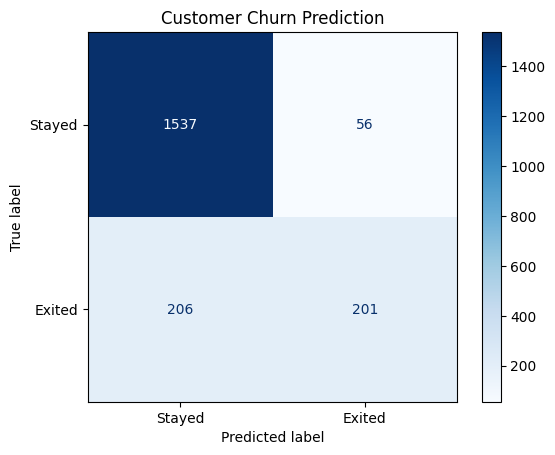

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["Stayed", "Exited"],
    cmap="Blues"
)

plt.title("Customer Churn Prediction")
plt.show()

In [9]:
customer = X_test.iloc[[0]]
prediction = best_model.predict(customer)[0]

if prediction == 1:
    print("Prediction: Customer may leave (Churn)")
else:
    print("Prediction: Customer may stay")

Prediction: Customer may stay
